# Active learning in astronomy
### A guided investigation with real, recorded experiments

A transient-classification model has a limited budget for acquiring new labels. Which candidates should it request—and how can we tell whether its choices actually help?

In the first notebook, you **ran** an active-learning loop. Here, you will **read and analyze its experimental history**: completed AstroMiNN runs that acquired labels over nine cycles. We will compare a few strategies at a time, measure label efficiency, and ask whether the results survive changes in random seed and the initial labeled set.

**Learning goals:** read an acquisition history; distinguish early and final performance; quantify seed variability; recognize why seemingly comparable experiments may not support a causal claim.

Everything below uses a small, included CSV of **real validation measurements**, plus NumPy, pandas and Matplotlib. No training, GPU, original astronomical cutouts, simulated data, or network connection is required.

## 1 · What was recorded?

The classification task has five target classes: **AGN, TDE, SN I, SN II, CV**. Each experiment starts with an initial labeled set, $L_0$. At each cycle a policy selects objects from an unlabeled candidate pool, their labels are revealed, and the classifier is retrained or continued according to that experiment's protocol.

The table we load contains the results of this process—not the candidates' hidden labels or their images. Each row records a policy, seed, acquisition cycle, number of labeled objects, and a **validation** metric.

We use validation macro-F1 (which treats classes equally when averaging F1) and balanced accuracy (average recall across classes). They summarize different aspects of performance; neither should be treated as a substitute for examining per-class mistakes.
We will also explore saved **per-class** results and **selection overlap**. These summaries are small enough to analyze on a laptop.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import display, Markdown
from al_pipeline.core.evaluation.notebook_style import use_notebook_style

# Figures are embedded in the executed GitHub notebook.
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')
USE_PRESENTATION_STYLE = True
if USE_PRESENTATION_STYLE:
    use_notebook_style()

# Works when Jupyter starts at the repository root OR inside examples/.
DATA_DIR = next((p for p in (Path('examples/data'), Path('data'))
                 if (p / 'astro_recent_validation.csv').is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError('Missing bundled examples/data/astro_recent_validation.csv')
records = pd.read_csv(DATA_DIR / 'astro_recent_validation.csv')
provenance = json.loads((DATA_DIR / 'astro_recent_provenance.json').read_text())
print('Data source: recorded AstroMiNN validation histories')
print(f"{len(records):,} metric rows; {records.groupby(['suite', 'strategy', 'seed']).ngroups} trajectories")
print('Metrics:', ', '.join(sorted(records.metric.unique())))

Data source: recorded AstroMiNN validation histories
1,020 metric rows; 51 trajectories
Metrics: balanced_accuracy, f1_macro


### First check the experimental contract

A learning curve is only meaningful if we know its horizontal axis. The original acquisition pool contains **4,253 candidate objects**. The recorded runs start from **476 labeled objects**, acquire **473 per cycle** for the first eight cycles, then acquire the remaining **469** in cycle nine. The final labeled set has **4,729 objects**.

We should verify those numbers from the CSV rather than assume every archive is complete.

In [2]:
REQUIRED = {'suite','strategy','seed','cycle','split','metric','value',
            'n_labeled','n_acquired_total'}
assert REQUIRED.issubset(records.columns)
assert set(records['split']) == {'validation'}
assert set(records['metric']) == {'f1_macro', 'balanced_accuracy'}
assert records['value'].notna().all()
assert not records.duplicated(['suite','strategy','seed','cycle','metric']).any()

expected_acquired = {0:0, **{c:473*c for c in range(1,9)}, 9:4253}
for (suite, policy, seed, metric), group in records.groupby(
        ['suite','strategy','seed','metric']):
    assert set(group.cycle) == set(range(10)), (suite, policy, seed, metric)
    observed = group.set_index('cycle')['n_acquired_total'].to_dict()
    assert observed == expected_acquired, (suite, policy, seed)
    assert (group.n_labeled == group.n_acquired_total + 476).all()

# One row per experimental point. Later plots never mix evaluation splits.
f1 = records.query("metric == 'f1_macro'").copy()
ba = records.query("metric == 'balanced_accuracy'").copy()
show = (f1.query("suite == 'astrominn_closed_loop_warm_v1' and strategy == 'random' and seed == 135")
        [['cycle','n_acquired_total','n_labeled','value']]
        .rename(columns={'n_acquired_total':'new labels','n_labeled':'total labels',
                         'value':'validation macro-F1'}))
display(show.head(5).round(3))
print('Contract checks passed: nine acquisitions, fixed validation split, no missing cycles.')

,cycle,new labels,total labels,validation macro-F1
0,0,0,476,0.568
2,1,473,949,0.596
4,2,946,1422,0.637
6,3,1419,1895,0.606
8,4,1892,2368,0.630


Contract checks passed: nine acquisitions, fixed validation split, no missing cycles.


## 2 · Compare acquisition strategies

We begin with **entropy**, **entropy + diversity**, and **BADGE**, using **random acquisition** as a baseline in the same figure. Entropy selects uncertain objects; the diversity-aware method discourages choosing very similar objects in one batch; BADGE uses gradient-based representations to select informative, varied examples.

Each curve is the mean of three runs. The dashed horizontal line marks the **independent historical full-data validation macro-F1** (63.67%); the point with vertical error bars at **Full** shows its mean ± standard deviation (0.74 percentage points). *Full* is a reference position, not another acquisition cycle. To keep the figure readable, we examine policy seed-to-seed variation later rather than adding error bars to every curve.

Entropy and entropy + diversity come from the same experimental suite. BADGE was recorded in a separate suite, so this figure is an **illustrative comparison**, not a controlled test of the methods. The horizontal axis counts newly acquired labels.


In [ ]:
SUITES = {
    'random': 'astrominn_closed_loop_warm_v1',
    'entropy': 'astrominn_closed_loop_warm_v1',
    'entropy_diversity': 'astrominn_closed_loop_warm_v1',
    'entropy_balanced_explore': 'astrominn_closed_loop_warm_v1',
    'bald': 'astrominn_task12_bald_mc20_v1',
    'tailor_diversity': 'astrominn_task13_tailor_pilot_v1',
    'uniform_mixture': 'astrominn_task13_tailor_pilot_v1',
    'similar_fl': 'astrominn_task14_similar_facility_v1',
    'similar_flcg': 'astrominn_task14_similar_facility_v1',
    'similar_flqmi_rare': 'astrominn_task14_similar_facility_v1',
    'direct': 'astrominn_task15_direct_vreduce_v1',
    'anchoral': 'astrominn_task18_anchoral_v1',
    'badge': 'astrominn_task11_advanced_acquisition_v1',
    'core_set': 'astrominn_task11_advanced_acquisition_v1',
    'fisher_batch': 'astrominn_task11_advanced_acquisition_v1',
}
LABELS = {'random':'Random', 'entropy':'Entropy',
          'entropy_diversity':'Entropy + diversity',
          'entropy_balanced_explore':'Entropy + exploration',
          'bald':'BALD', 'tailor_diversity':'TAILOR',
          'uniform_mixture':'Uniform mixture',
          'similar_fl':'SIMILAR · FL', 'similar_flcg':'SIMILAR · FLCG',
          'similar_flqmi_rare':'SIMILAR · rare',
          'direct':'DIRECT', 'anchoral':'AnchorAL',
          'badge':'BADGE', 'core_set':'Core-set', 'fisher_batch':'Fisher batch'}
COLORS = {'random':'#98B5A6', 'entropy':'#83B6CD',
          'entropy_diversity':'#AE9DC7', 'entropy_balanced_explore':'#DEA2AD',
          'bald':'#519C9A', 'tailor_diversity':'#AE9DC7',
          'uniform_mixture':'#B7A588', 'direct':'#83B6CD',
          'anchoral':'#DEA2AD'}

def history_for(policy, *, metric='f1_macro', alternate_l0=False):
    suite = ('astrominn_task17_random_l0_v1' if alternate_l0
             else SUITES[policy])
    subset = records[(records.suite == suite) & (records.strategy == policy) &
                     (records.metric == metric)]
    if subset.empty:
        raise ValueError(f'No recorded history for {suite}/{policy}/{metric}')
    return subset.copy()

# Independent historical full-data validation benchmark (mean ± SD).
FULL_DATA_F1 = 0.6367
FULL_DATA_F1_SD = 0.0074
FULL_REFERENCE_X = 4680  # symbolic "Full" point, not a new-label count

def add_full_data_reference(ax):
    """Display the historical benchmark without mixing test and validation."""
    ax.axhline(FULL_DATA_F1, color='#747D83', linestyle='--', linewidth=1.5,
               alpha=.9, label='Full-data reference', zorder=1)
    ax.errorbar([FULL_REFERENCE_X], [FULL_DATA_F1], yerr=[FULL_DATA_F1_SD],
                fmt='o', markersize=5, capsize=3, elinewidth=1.4,
                color='#747D83', zorder=6, clip_on=False, label='_nolegend_')

def curve(ax, policies, *, metric='f1_macro', alternate_l0=False):
    """Show requested policies, automatically adding random on macro-F1 plots."""
    policies = tuple(policies)
    if not 1 <= len(policies) <= 4:
        raise ValueError('Use one to four selected policies per figure')
    if metric == 'f1_macro' and 'random' not in policies:
        policies = ('random', *policies)
    for policy in policies:
        group = history_for(policy, metric=metric, alternate_l0=alternate_l0)
        averaged = (group.groupby('cycle', as_index=False)
                    .agg(x=('n_acquired_total','mean'), score=('value','mean')))
        ax.plot(averaged.x, averaged.score,
                label=LABELS.get(policy,policy), color=COLORS.get(policy,'#77858D'),
                marker='o', markevery=[0,2,4,6,9], markersize=3.5, linewidth=2.1)
    if metric == 'f1_macro':
        add_full_data_reference(ax)
    ax.set(xlabel='New labels acquired (Full = historical reference)',
           ylabel=('Validation macro-F1' if metric=='f1_macro'
                   else 'Validation balanced accuracy'),
           xlim=(-110,4970) if metric=='f1_macro' else (-110,4360),
           ylim=(.49,.71))
    ax.set_xticks([0,946,1892,2838,4253,FULL_REFERENCE_X]
                  if metric=='f1_macro' else [0,946,1892,2838,4253])
    if metric == 'f1_macro':
        ax.set_xticklabels(['0','946','1,892','2,838','4,253','Full'])
    ax.grid(axis='y', linewidth=.7, alpha=.65)
    ax.grid(axis='x', visible=False)
    ax.legend(loc='lower right', ncol=1, frameon=False)
    return ax

fig, ax = plt.subplots(figsize=(8.6,4.5))
curve(ax, ('badge','entropy','entropy_diversity'))
ax.set_title('Uncertainty, diversity, and BADGE', loc='left')
plt.tight_layout(); plt.show()

**Reading the figure.** Ask when each policy first moves above its starting performance, whether any curve decreases after acquiring more labels, and whether the policy with the highest early score also has the highest final score. Fluctuations may reflect optimization, sampling, and finite validation support—not necessarily worse acquired objects.

**Exercise 1 — Label-efficiency question.** Using `f1`, find the first cycle where the *mean* BADGE, entropy or entropy-plus-diversity macro-F1 exceeds a threshold of your choice, for example 0.64. Report both the cycle number and the number of newly labeled objects. What changes if you require **all three seeds** to pass the threshold?

In [4]:
# Exercise 1 (intentionally unsolved):
THRESHOLD = 0.64
# TODO: Compute the first crossing for each policy's *mean* learning curve.
# TODO: Repeat using a stricter all-seeds criterion; compare your answers.

## 3 · Compare more advanced acquisition rules

Predictive entropy uses a single distribution over class probabilities; BALD estimates model disagreement under stochastic predictions; TAILOR combines acquisition signals with a diversity-aware selection rule. A uniform mixture offers a useful comparator to the learned weighting.

We now look at **BALD, TAILOR, and the uniform mixture**, alongside a **random-acquisition** baseline and the historical full-data reference. All have the same recorded baseline macro-F1 for each seed and the same labeling budgets.

**Important limitation:** these policies originate in *different experiment suites*. Matching baselines and budgets are helpful checks, but they do **not establish that every training, checkpoint, or policy-implementation detail was identical**. Treat the next plot as a descriptive comparison of archived runs, not a controlled claim of superiority.

In [ ]:
ADVANCED = ('bald','tailor_diversity','uniform_mixture')
# Check what we can establish from the supplied validation histories.
base = {}
for name in ('random', *ADVANCED):
    part = history_for(name).query('cycle == 0').set_index('seed')
    base[name] = part.value.sort_index()
baseline_table = pd.DataFrame(base)
assert np.allclose(baseline_table.to_numpy(),
                   baseline_table['random'].to_numpy()[:,None])
print('Recorded cycle-zero macro-F1 agrees for these four policies by seed.')
display(baseline_table.round(3))

fig, ax = plt.subplots(figsize=(8.6,4.5))
curve(ax, ADVANCED)
ax.set_title('Advanced acquisition strategies — descriptive comparison', loc='left')
plt.tight_layout(); plt.show()

### What should we mean by “best”?

A decision made after cycle 2 is different from one made after cycle 9. Compare policies at **the same label budget**. You can also summarize performance across several early cycles rather than judge one possibly noisy checkpoint.

The table below computes, for each policy, the average score at cycle 2, the score at the final cycle, and the mean over cycles 1–5. That final quantity is an *unweighted mean over equally spaced acquisition stages*, not a continuous area-under-curve estimate.

In [6]:
OVERVIEW = ('random','entropy','entropy_diversity','bald',
            'tailor_diversity','uniform_mixture')
summary_rows = []
for policy in OVERVIEW:
    group = history_for(policy)
    mean_by_cycle = group.groupby('cycle').value.mean()
    summary_rows.append({
        'policy': LABELS[policy],
        'cycle 2': mean_by_cycle.loc[2],
        'cycles 1–5 mean': mean_by_cycle.loc[1:5].mean(),
        'cycle 9': mean_by_cycle.loc[9],
        'cycle 2 SD': group.query('cycle == 2').value.std(ddof=1),
    })
summary = pd.DataFrame(summary_rows).set_index('policy')
display(summary.round(3))

,cycle 2,cycles 1–5 mean,cycle 9,cycle 2 SD
policy,,,,
Random,0.619,0.612,0.634,0.018
Entropy,0.604,0.619,0.652,0.005
Entropy + diversity,0.642,0.630,0.655,0.015
BALD,0.653,0.637,0.660,0.009
TAILOR,0.652,0.639,0.654,0.010
Uniform mixture,0.638,0.640,0.645,0.022


**Exercise 2 — Define a criterion before ranking.** Choose an early-cycle score, a final score, or an area-under-the-learning-curve measure. Write code to rank the strategies using *one* definition. Does your ranking change with the definition? Why should it be chosen **before** looking at validation results?

In [7]:
# Exercise 2 (intentionally unsolved):
# TODO: Compute a normalized trapezoidal area under macro-F1 versus
#       new labels acquired, over cycles 0–5 (same budget for every policy).
# TODO: Compare this ranking with the cycle-9 ranking.

## 4 · Which transient classes benefit?

**Macro-F1 averages performance across the five classes**, so it cannot show which individual classes improved. We also have the recorded validation precision, recall, and F1 for each class—no new model evaluation is needed.

Consider **TDEs (17 validation objects)** and **CVs (92 objects)**. The plots compare three strategies, with each line again showing a mean across three seeds. Notice that the rare TDE class behaves differently from CVs and is especially sensitive to individual classification mistakes.


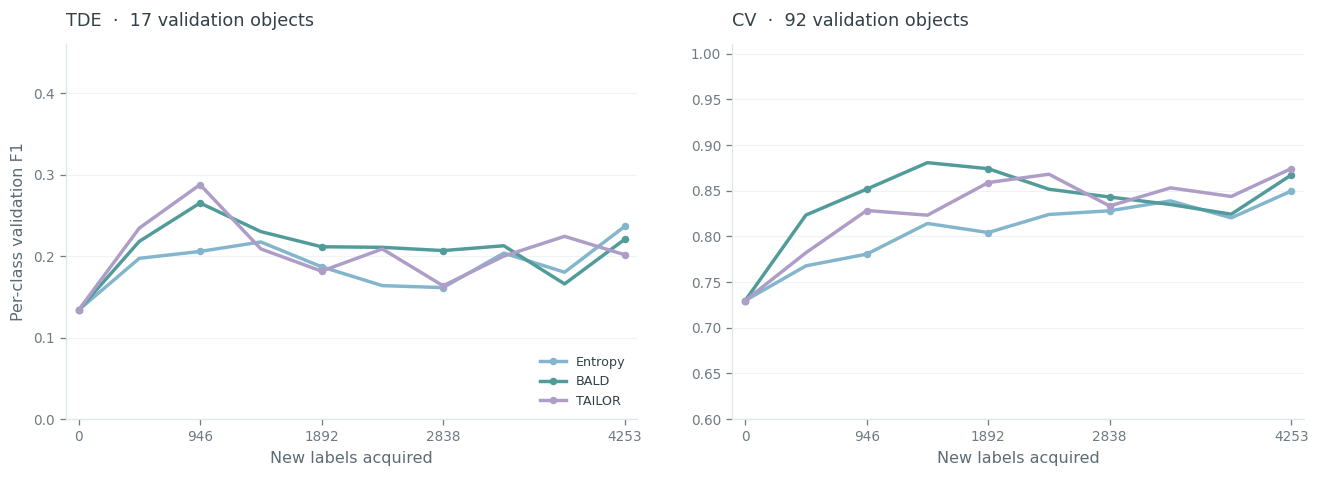

At cycle 2, the TDE scores are:


,precision,recall,f1
Entropy,0.129,0.529,0.203
BALD,0.182,0.510,0.265
TAILOR,0.187,0.627,0.288


In [8]:
# Class-level scores were calculated during the original experiments.
per_class = pd.read_csv(DATA_DIR / 'astro_recent_per_class.csv')
assert set(per_class.class_name) == {'AGN','TDE','SN I','SN II','CV'}
assert per_class.groupby('class_name').support.nunique().eq(1).all()
assert per_class[per_class.class_name == 'TDE'].support.iloc[0] == 17
assert per_class[per_class.class_name == 'CV'].support.iloc[0] == 92

CLASS_POLICIES = ('entropy', 'bald', 'tailor_diversity')
fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.25), sharex=True)
for ax, class_name, ylim in zip(axes, ('TDE', 'CV'), ((0, .46), (.60, 1.01))):
    for policy in CLASS_POLICIES:
        rows = per_class[(per_class.suite == SUITES[policy]) &
                         (per_class.strategy == policy) &
                         (per_class.class_name == class_name)]
        mean = (rows.groupby('cycle', as_index=False)
                .agg(labels=('n_acquired_total', 'mean'), score=('f1', 'mean')))
        ax.plot(mean.labels, mean.score, color=COLORS[policy],
                linewidth=2.15, marker='o', markevery=[0,2,4,6,9],
                markersize=3.7, label=LABELS[policy])
    n = int(per_class.query('class_name == @class_name').support.iloc[0])
    ax.set_title(f'{class_name}  ·  {n} validation objects', loc='left')
    ax.set(xlim=(-100, 4350), ylim=ylim, xlabel='New labels acquired')
    ax.set_xticks([0,946,1892,2838,4253])
    ax.grid(axis='y', alpha=.60)
    ax.grid(axis='x', visible=False)
axes[0].set_ylabel('Per-class validation F1')
axes[0].legend(loc='lower right', frameon=False)
plt.tight_layout(w_pad=2.9)
plt.show()

print('At cycle 2, the TDE scores are:')
tde_cycle2 = (per_class[(per_class.cycle == 2) &
                        (per_class.class_name == 'TDE') &
                        (per_class.strategy.isin(CLASS_POLICIES))]
              .groupby('strategy')[['precision','recall','f1']].mean()
              .reindex(CLASS_POLICIES))
tde_cycle2.index = [LABELS[k] for k in tde_cycle2.index]
display(tde_cycle2.round(3))

## 5 · Do the methods select the same objects?

Two strategies can obtain similar classification scores while requesting **different objects**. The **Jaccard overlap** compares their selected sets: an overlap of 100% means identical sets, while 0% means no shared objects.

The matrix shows **cumulative overlap through cycle 2**. Each policy has acquired 946 objects (two batches); the shared initial labeled set is excluded. Percentages are averaged across three corresponding seeds. The blue scale follows the acquisition-overlap figures used in the research presentation.

**Reading prompt:** Which pair has the most similar selections? Does a high overlap necessarily imply better classification performance?


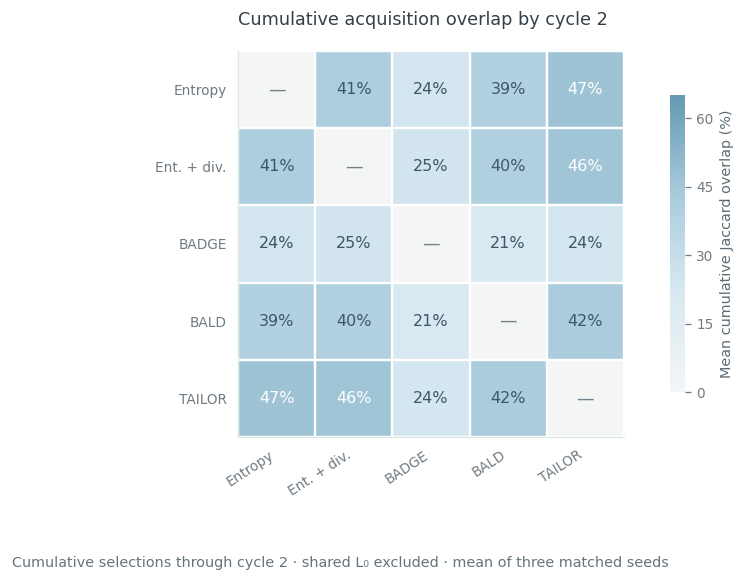

In [9]:
from matplotlib.colors import LinearSegmentedColormap

# Saved, anonymized comparisons: no individual candidate IDs are distributed.
overlap_by_seed = pd.read_csv(DATA_DIR / 'astro_cycle2_overlap_by_seed.csv')
overlap_means = pd.read_csv(DATA_DIR / 'astro_cycle2_overlap_mean.csv')
assert set(overlap_by_seed.seed) == {135, 246, 357}
assert overlap_by_seed.groupby(['policy_a','policy_b']).seed.nunique().eq(3).all()
assert (overlap_by_seed.cumulative_intersection <= 946).all()
assert (overlap_by_seed.cumulative_union >= 946).all()
recomputed = overlap_by_seed.groupby(['policy_a','policy_b']).cumulative_jaccard.mean()
provided = overlap_means.set_index(['policy_a','policy_b']).cumulative_mean
assert np.allclose(recomputed.loc[provided.index], provided)

ORDER = ('entropy','entropy_diversity','badge','bald','tailor_diversity')
SHORT_NAMES = ('Entropy','Ent. + div.','BADGE','BALD','TAILOR')
values = np.full((len(ORDER),len(ORDER)), np.nan)
for (a,b), score in recomputed.items():
    i,j = ORDER.index(a),ORDER.index(b)
    if i != j:
        values[i,j] = values[j,i] = 100*score
assert np.allclose(values, values.T, equal_nan=True)

cmap = LinearSegmentedColormap.from_list(
    'presentation_blues', ['#F2F6F8','#D9E9F1','#A8CBDC','#6599B3'])
cmap.set_bad('#F4F6F6')
fig, ax = plt.subplots(figsize=(8.1,5.5))
heat = ax.imshow(np.ma.masked_invalid(values),cmap=cmap,vmin=0,vmax=65)
ax.set_xticks(range(len(ORDER)),SHORT_NAMES,rotation=33,ha='right')
ax.set_yticks(range(len(ORDER)),SHORT_NAMES)
ax.tick_params(axis='both',length=0,pad=7)
for i in range(len(ORDER)):
    for j in range(len(ORDER)):
        if i == j:
            ax.text(j,i,'—',ha='center',va='center',color='#73818A',fontsize=11)
        else:
            value = values[i,j]
            ax.text(j,i,f'{value:.0f}%',ha='center',va='center',
                    color='white' if value>=43 else '#3D5768',fontsize=10)
for edge in np.arange(-.5,len(ORDER),1):
    ax.axhline(edge,color='white',linewidth=1.5)
    ax.axvline(edge,color='white',linewidth=1.5)
ax.set_title('Cumulative acquisition overlap by cycle 2',loc='left',pad=16)
bar = fig.colorbar(heat,ax=ax,fraction=.05,pad=.07,shrink=.77)
bar.set_label('Mean cumulative Jaccard overlap (%)',fontsize=9)
bar.set_ticks([0,15,30,45,60])
bar.outline.set_visible(False)
fig.subplots_adjust(left=.19,right=.90,bottom=.26,top=.87)
fig.text(.51,.055,
         'Cumulative selections through cycle 2 · shared L₀ excluded · mean of three matched seeds',
         ha='center',fontsize=9,color='#64747D')
plt.show()

## 6 · Don't hide the individual seeds

A mean curve is easy to read, but can hide unstable behavior. Here we intentionally isolate **one policy**, BALD, so the three individual seed trajectories remain visible without covering the entire figure in error bars.

The three pale lines are individual BALD training seeds (135, 246, 357); the darker BALD line is their mean. The green line shows the random-acquisition three-seed mean, while the dashed line and marked point show the independent historical full-data reference (mean ± SD). Compare the spread near cycle 2 with the spread at the end. A visible difference across only three seeds is descriptive, **not** a confidence interval or proof of statistical significance.

In [ ]:
seed_data = history_for('bald')
fig, ax = plt.subplots(figsize=(8.6,4.4))
for seed, group in seed_data.groupby('seed'):
    group = group.sort_values('cycle')
    ax.plot(group.n_acquired_total, group.value,
            color='#B8CCD0', linewidth=1.35, alpha=.83,
            marker='o', markersize=2.7, label='_nolegend_')
mean = (seed_data.groupby('cycle',as_index=False)
        .agg(x=('n_acquired_total','mean'), score=('value','mean')))
ax.plot(mean.x,mean.score,color=COLORS['bald'],linewidth=2.7,
        marker='o',markevery=[0,2,4,6,9],markersize=4.2,label='BALD mean')
random_mean = (history_for('random').groupby('cycle',as_index=False)
               .agg(x=('n_acquired_total','mean'), score=('value','mean')))
ax.plot(random_mean.x,random_mean.score,color=COLORS['random'],linewidth=1.9,
        marker='o',markevery=[0,2,4,6,9],markersize=3.2,label='Random mean')
add_full_data_reference(ax)
ax.set(xlim=(-110,4970),ylim=(.49,.71),
       xlabel='New labels acquired (Full = historical reference)',
       ylabel='Validation macro-F1')
ax.set_xticks([0,946,1892,2838,4253,FULL_REFERENCE_X])
ax.set_xticklabels(['0','946','1,892','2,838','4,253','Full'])
ax.set_title('BALD · the mean and the three individual histories',loc='left')
ax.grid(axis='y',alpha=.65);ax.grid(axis='x',visible=False)
ax.legend(frameon=False,loc='lower right')
plt.tight_layout();plt.show()

**Exercise 3 — Stability.** For BALD and TAILOR, compute the between-seed standard deviation at cycles 2 and 9. Is the method with the largest mean necessarily the one with the smallest variation? For an extra challenge, repeat the calculation with balanced accuracy instead of macro-F1.

In [11]:
# Exercise 3 (intentionally unsolved):
# TODO: Group each policy's per-seed scores by cycle.
# TODO: Report and interpret variability at early and late cycles.

## 7 · What happens when the initial labeled set changes?

Our earlier plots deliberately used the original initial labeled set, $L_0$. A second set of completed runs used a **different $L_0$**, while keeping 476 starting labels. We do *not* blend those results into the preceding policy ranking.

Instead, compare **random versus entropy separately for each initialization**. The two panels use the same axes and colors, with the historical full-data benchmark drawn in both panels, so differences remain visible without adding four overlapping policy curves to one plot.

This is a sensitivity analysis. A changed starting score signals that initial data matter; it does not, by itself, identify why the subsequent trajectories differ.

In [ ]:
fig, axes = plt.subplots(1,2,figsize=(12,4.35),sharex=True,sharey=True)
curve(axes[0],('random','entropy'))
curve(axes[1],('random','entropy'),alternate_l0=True)
axes[0].set_title('Original initial labeled set',loc='left')
axes[1].set_title('Alternative initial labeled set',loc='left')
axes[1].set_ylabel('')
for ax in axes:
    ax.legend(loc='lower right',frameon=False)
fig.subplots_adjust(wspace=.14)
plt.show()

for alternate, label in ((False,'Original L0'),(True,'Alternative L0')):
    for policy in ('random','entropy'):
        group = history_for(policy,alternate_l0=alternate)
        print(f"{label:15} | {LABELS[policy]:7} | "
              f"initial {group.query('cycle == 0').value.mean():.3f} | "
              f"final {group.query('cycle == 9').value.mean():.3f}")

**Exercise 4 — Fair comparisons.** What aspects of the protocol must match before interpreting a difference between acquisition methods as a policy effect? Consider the initial object IDs, the validation split, training objective, initialization/continuation, checkpoint selection, and total budget. Explain why equal cycle-zero scores alone would not settle the question.

**Optional coding extension:** Change the `policies` argument of `curve` to inspect two or three methods from Task 11 (BADGE, core-set or Fisher batch), or the SIMILAR variants. Keep each figure to three lines or fewer, and retain the suite identity in your analysis.

## 8 · Closing thought

Acquisition methods can obtain similar overall scores while learning different classes and selecting different objects. Here we studied **recorded experiments**; rerunning AstroMiNN on raw observations would require the original data and substantially more computing resources.
